In [1]:
# Jika library belum ada: %pip install -q torch torchvision numpy pandas matplotlib scikit-image "torchmetrics[image]"
from pathlib import Path
import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import ConcatDataset, Subset, DataLoader
from torchvision import datasets, transforms
from skimage.metrics import structural_similarity as ssim

SEED, BATCH, LATENT, EPOCHS, LR, BETA = 42, 128, 64, 15, 1e-3, 1.0
FID_SAMPLES = 2048  # gunakan jumlah & fitur yang sama pada VAE, GAN, DCGAN, DDPM
OUT = Path('outputs/vae')
OUT.mkdir(parents=True, exist_ok=True)
SPLIT_FILE = Path('fashion_mnist_split_seed42.npz')
MODEL_FILE = OUT / 'best_vae.pt'

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [2]:
transform = transforms.ToTensor()  # nilai piksel [0,1], cocok dengan output sigmoid dan BCE
full = ConcatDataset([
    datasets.FashionMNIST('data', train=True, download=True, transform=transform),
    datasets.FashionMNIST('data', train=False, download=True, transform=transform),
])

if SPLIT_FILE.exists():
    s = np.load(SPLIT_FILE)
    train_idx, val_idx, test_idx = s['train_idx'], s['val_idx'], s['test_idx']
else:
    idx = torch.randperm(len(full), generator=torch.Generator().manual_seed(SEED)).numpy()
    train_idx, val_idx, test_idx = idx[:56000], idx[56000:63000], idx[63000:]
    np.savez_compressed(SPLIT_FILE, train_idx=train_idx, val_idx=val_idx, test_idx=test_idx)

assert (len(train_idx), len(val_idx), len(test_idx)) == (56000, 7000, 7000)
assert len(np.unique(np.r_[train_idx, val_idx, test_idx])) == len(full)
train_set, val_set, test_set = [Subset(full, a.tolist()) for a in
                                (train_idx, val_idx, test_idx)]
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader  = DataLoader(val_set, batch_size=BATCH, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH, shuffle=False)
print('Train / Val / Test:', len(train_set), len(val_set), len(test_set))

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 17.4MB/s]

Train / Val / Test: 56000 7000 7000


## 3. Model VAE

Encoder menghasilkan **μ** dan **log σ²**, bukan satu vektor deterministik. Saat training, ambil sampel dengan *reparameterization trick*: \(z=\mu+\epsilon\exp(0.5\log\sigma^2)\), \(\epsilon\sim\mathcal N(0,I)\). Saat rekonstruksi test/interpolasi gunakan \(z=\mu\) agar stabil.

Objektif training per gambar: \(\mathrm{BCE}_{sum}(x,\hat x)+\beta D_{KL}(q_\phi(z|x)\|\mathcal N(0,I))\). MSE, PSNR, SSIM hanya untuk **evaluasi** agar sebanding dengan AE.

In [3]:
class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU())
        self.mu = nn.Linear(256, LATENT)
        self.logvar = nn.Linear(256, LATENT)
        self.decoder = nn.Sequential(nn.Linear(LATENT, 256), nn.ReLU(),
                                     nn.Linear(256, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.encoder(x)
        return self.mu(h), self.logvar(h)

    def decode(self, z):
        return self.decoder(z).reshape(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)  # reparameterization
        return self.decode(z), mu, logvar

    def reconstruct(self, x):
        mu, _ = self.encode(x)
        return self.decode(mu)

    def sample(self, n):
        return self.decode(torch.randn(n, LATENT, device=next(self.parameters()).device))

model = VAE().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
num_params = sum(p.numel() for p in model.parameters())
print(f'Jumlah parameter: {num_params:,}')

Jumlah parameter: 451,984


## 4. Training + validation

Model terbaik dipilih dari **validation ELBO loss** (BCE + β KL), bukan test set. Simpan rekonstruksi BCE dan KL secara terpisah agar bisa dianalisis.

In [4]:
def sync():
    if device.type == 'cuda': torch.cuda.synchronize()
    elif device.type == 'mps': torch.mps.synchronize()

def run_epoch(loader, training=False):
    model.train(training)
    total_bce, total_kl, n = 0.0, 0.0, 0
    with torch.set_grad_enabled(training):
        for x, _ in loader:
            x = x.to(device)
            if training: optimizer.zero_grad()
            recon, mu, logvar = model(x)
            bce = F.binary_cross_entropy(recon, x, reduction='sum') / len(x)
            kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum() / len(x)
            loss = bce + BETA * kl
            if training:
                loss.backward()
                optimizer.step()
            total_bce += bce.item() * len(x)
            total_kl += kl.item() * len(x)
            n += len(x)
    bce, kl = total_bce/n, total_kl/n
    return bce, kl, bce + BETA*kl

history, best_val, best_epoch = [], float('inf'), 0
for epoch in range(1, EPOCHS + 1):
    sync(); start = time.perf_counter()
    train_bce, train_kl, train_loss = run_epoch(train_loader, True)
    sync(); seconds = time.perf_counter() - start
    val_bce, val_kl, val_loss = run_epoch(val_loader)
    history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
                    'train_bce': train_bce, 'train_kl': train_kl,
                    'val_bce': val_bce, 'val_kl': val_kl, 'training_time_s': seconds})
    if val_loss < best_val:
        best_val, best_epoch = val_loss, epoch
        torch.save(model.state_dict(), MODEL_FILE)
    print(f'Epoch {epoch:02} | Train {train_loss:.2f} (BCE {train_bce:.1f}, KL {train_kl:.1f})'
          f' | Val {val_loss:.2f} | {seconds:.1f}s')

history_df = pd.DataFrame(history)
history_df.to_csv(OUT / 'vae_history.csv', index=False)
model.load_state_dict(torch.load(MODEL_FILE, map_location=device, weights_only=True))
model.eval()
print('Best epoch:', best_epoch)

Epoch 01 | Train 299.85 (BCE 285.1, KL 14.7) | Val 274.33 | 7.4s
Epoch 02 | Train 267.70 (BCE 251.1, KL 16.6) | Val 263.11 | 7.4s
Epoch 03 | Train 258.54 (BCE 242.9, KL 15.6) | Val 255.82 | 9.2s
Epoch 04 | Train 253.07 (BCE 238.0, KL 15.1) | Val 252.31 | 7.1s
Epoch 05 | Train 250.07 (BCE 235.0, KL 15.1) | Val 250.31 | 7.2s
Epoch 06 | Train 248.20 (BCE 233.0, KL 15.2) | Val 248.49 | 6.4s
Epoch 07 | Train 246.92 (BCE 231.7, KL 15.2) | Val 247.66 | 7.1s
Epoch 08 | Train 245.98 (BCE 230.6, KL 15.3) | Val 246.47 | 6.7s
Epoch 09 | Train 245.28 (BCE 229.9, KL 15.4) | Val 246.26 | 6.5s
Epoch 10 | Train 244.60 (BCE 229.1, KL 15.5) | Val 245.36 | 7.4s
Epoch 11 | Train 244.20 (BCE 228.6, KL 15.6) | Val 245.01 | 6.4s
Epoch 12 | Train 243.84 (BCE 228.2, KL 15.6) | Val 244.88 | 7.0s
Epoch 13 | Train 243.46 (BCE 227.8, KL 15.6) | Val 244.39 | 6.5s
Epoch 14 | Train 243.21 (BCE 227.5, KL 15.7) | Val 244.04 | 6.6s
Epoch 15 | Train 242.89 (BCE 227.2, KL 15.7) | Val 244.04 | 7.0s
Best epoch: 15


## 5. Evaluasi pada test set + inference latency

Rekonstruksi test menggunakan latent **μ** (tanpa noise), sedangkan latency generatif mengukur **decoder dari z acak** untuk 64 gambar; itulah operasi VAE yang sebanding dengan generator GAN.

In [5]:
errors, psnr_values, ssim_values = 0.0, [], []
with torch.inference_mode():
    for x, _ in test_loader:
        x = x.to(device)
        recon = model.reconstruct(x)
        errors += F.mse_loss(recon, x, reduction='sum').item()
        mse_img = (recon - x).square().flatten(1).mean(1)
        psnr_values.extend((10 * torch.log10(1 / mse_img.clamp_min(1e-12))).cpu().tolist())
        ssim_values.extend(ssim(a[0], b[0], data_range=1.0)
                           for a, b in zip(x.cpu().numpy(), recon.cpu().numpy()))

test_mse = errors / (len(test_set) * 28 * 28)
test_psnr = float(np.mean(psnr_values))
test_ssim = float(np.mean(ssim_values))

z64 = torch.randn(64, LATENT, device=device)  # tetap selama benchmark (hanya decode)
with torch.inference_mode():
    for _ in range(10): model.decode(z64)  # warmup
    timings = []
    for _ in range(30):
        sync(); start = time.perf_counter()
        model.decode(z64)
        sync(); timings.append((time.perf_counter() - start)*1000)
latency = float(np.mean(timings))
print(f'Test MSE    : {test_mse:.6f}')
print(f'Test PSNR   : {test_psnr:.3f} dB')
print(f'Test SSIM   : {test_ssim:.4f}')
print(f'Latency gen : {latency:.3f} ± {np.std(timings):.3f} ms / batch 64')

Test MSE    : 0.014139
Test PSNR   : 19.305 dB
Test SSIM   : 0.6933
Latency gen : 0.165 ± 0.019 ms / batch 64


## 6. Empat visualisasi wajib

**Figur 1** (rekonstruksi 8 gambar), **Figur 2** (16 sampel acak), **Figur 4** (interpolasi latent 6 titik), **Figur 5** (kurva loss). Semuanya disimpan sebagai PNG.

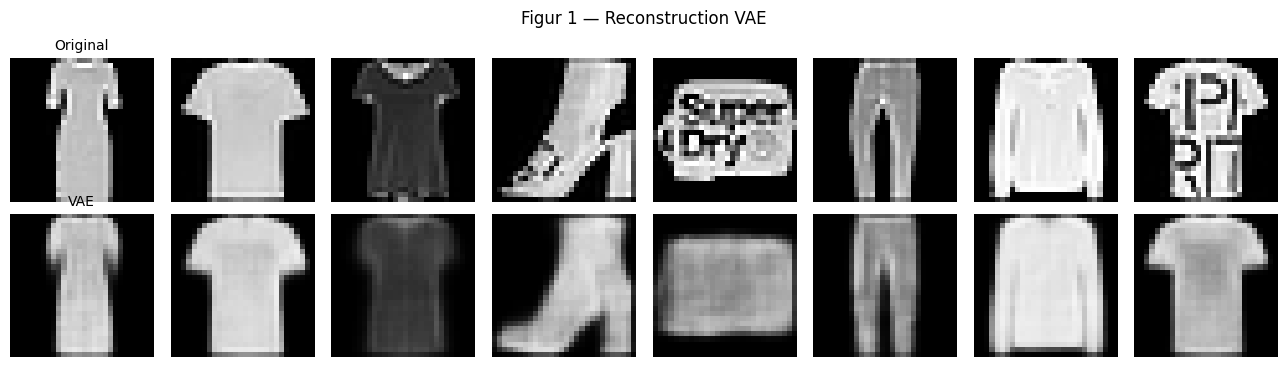

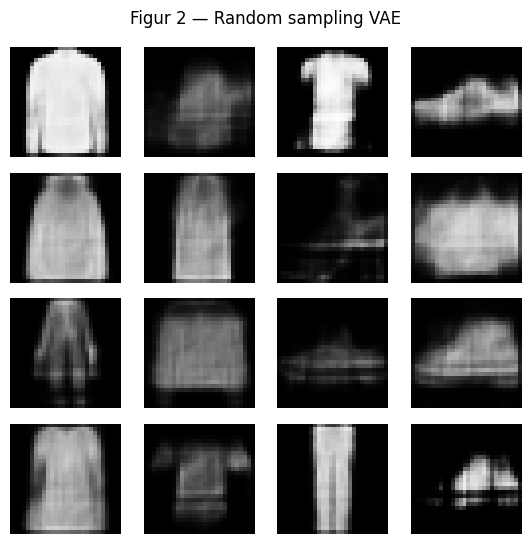

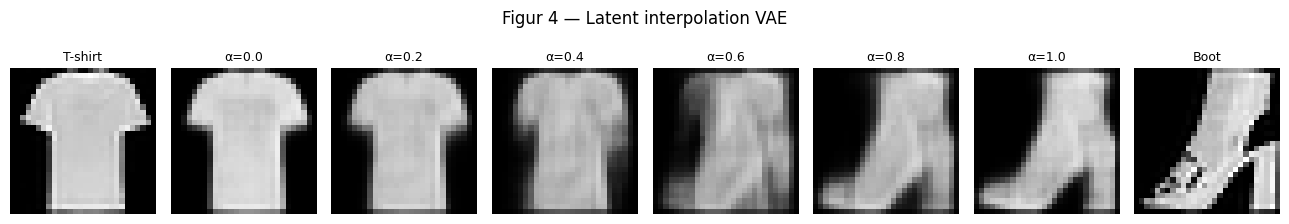

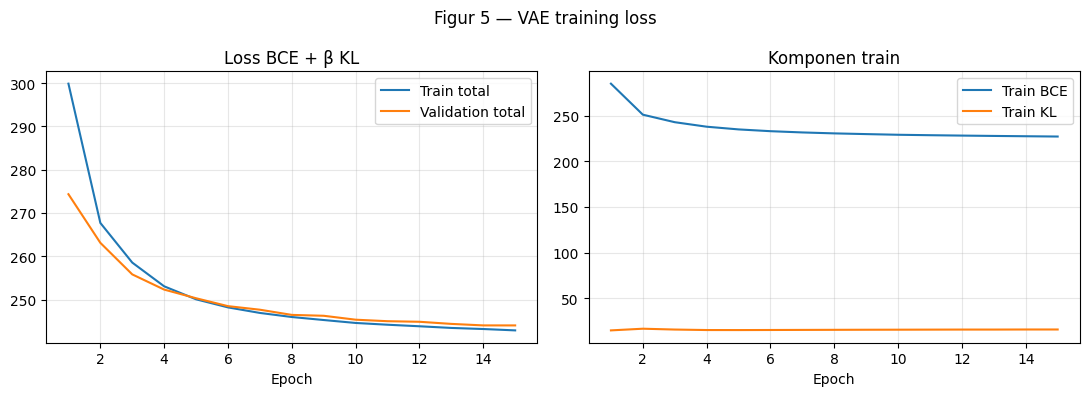

In [6]:
# Figur 1 — Rekonstruksi (baris atas asli, baris bawah VAE)
x8 = next(iter(test_loader))[0][:8].to(device)
with torch.inference_mode(): recon8 = model.reconstruct(x8).cpu()
fig, axes = plt.subplots(2, 8, figsize=(13, 3.7))
for i in range(8):
    axes[0, i].imshow(x8[i,0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[1, i].imshow(recon8[i,0], cmap='gray', vmin=0, vmax=1)
    for row in axes: row[i].axis('off')
axes[0,0].set_title('Original', fontsize=10)
axes[1,0].set_title('VAE', fontsize=10)
fig.suptitle('Figur 1 — Reconstruction VAE')
plt.tight_layout(); plt.savefig(OUT/'figure1_vae_reconstruction.png', dpi=200); plt.show()

# Figur 2 — Generasi 16 gambar dari z ~ N(0,I)
with torch.inference_mode(): generated = model.sample(16).cpu()
fig, axes = plt.subplots(4,4,figsize=(5.5,5.5))
for ax, im in zip(axes.flat, generated):
    ax.imshow(im[0], cmap='gray', vmin=0, vmax=1); ax.axis('off')
fig.suptitle('Figur 2 — Random sampling VAE')
plt.tight_layout(); plt.savefig(OUT/'figure2_vae_samples.png', dpi=200); plt.show()

# Figur 4 — Latent interpolation: T-shirt (kelas 0) → ankle boot (kelas 9)
def sample_of_class(target):
    for x, label in test_set:
        if label == target: return x.unsqueeze(0).to(device)
    raise ValueError('Kelas tidak ditemukan')
x_a, x_b = sample_of_class(0), sample_of_class(9)
alphas = np.linspace(0,1,6)
with torch.inference_mode():
    z_a, _ = model.encode(x_a); z_b, _ = model.encode(x_b)
    zz = torch.cat([(1-float(a))*z_a + float(a)*z_b for a in alphas])
    imgs = model.decode(zz).cpu()
fig, axes = plt.subplots(1,8,figsize=(13,2.4))
for i, ax in enumerate(axes):
    im = x_a[0,0].cpu() if i==0 else x_b[0,0].cpu() if i==7 else imgs[i-1,0]
    ax.imshow(im,cmap='gray',vmin=0,vmax=1)
    ax.set_title('T-shirt' if i==0 else 'Boot' if i==7 else f'α={alphas[i-1]:.1f}',fontsize=9)
    ax.axis('off')
fig.suptitle('Figur 4 — Latent interpolation VAE')
plt.tight_layout(); plt.savefig(OUT/'figure4_vae_interpolation.png',dpi=200); plt.show()

# Figur 5 — Training loss (total ELBO, reconstruction BCE, KL)
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].plot(history_df.epoch,history_df.train_loss,label='Train total')
axes[0].plot(history_df.epoch,history_df.val_loss,label='Validation total')
axes[0].set_title('Loss BCE + β KL'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(history_df.epoch,history_df.train_bce,label='Train BCE')
axes[1].plot(history_df.epoch,history_df.train_kl,label='Train KL')
axes[1].set_title('Komponen train'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(alpha=.3)
fig.suptitle('Figur 5 — VAE training loss')
plt.tight_layout(); plt.savefig(OUT/'figure5_vae_loss.png',dpi=200); plt.show()

## 7. FID (generative quality)

Metrik FID hanya untuk **gambar baru dari prior** \(z\sim\mathcal N(0,I)\), bukan rekonstruksi. Dibandingkan dengan test set yang sama. Menggunakan `torchmetrics[image]`/`torch-fidelity` dan fitur Inception **2048**. Komputasi ini lebih berat daripada evaluasi MSE; memerlukan pengunduhan bobot Inception pertama kali. Jika library belum tersedia, jalankan `%pip install -q "torchmetrics[image]"` lalu ulangi cell ini.

**Catatan metodologi:** `FID_SAMPLES=2048` cukup untuk prototipe, tetapi FID pada sampel kecil bisa bervariasi; untuk laporan final pertimbangkan menggunakan hingga 7000 gambar test dan jumlah sampel sama untuk model-model generatif.

In [8]:
%pip install -q "torchmetrics[image]"

In [9]:
from torchmetrics.image.fid import FrechetInceptionDistance

# GPU CUDA jika tersedia; CPU pada Mac/MPS demi kompatibilitas operasi Inception/FID.
fid_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
metric = FrechetInceptionDistance(feature=2048, normalize=True).to(fid_device)
metric.set_dtype(torch.float64)

seen = 0
with torch.inference_mode():
    for x, _ in test_loader:
        if seen >= FID_SAMPLES: break
        x = x[:FID_SAMPLES-seen]
        fake = model.sample(len(x)).detach().to(fid_device)
        # FID Inception menerima RGB; grayscale diduplikasi menjadi 3 channel.
        metric.update(x.to(fid_device).repeat(1,3,1,1), real=True)
        metric.update(fake.repeat(1,3,1,1), real=False)
        seen += len(x)
        if seen % 512 == 0: print('FID:', seen, '/', FID_SAMPLES)
fid_score = float(metric.compute().item())
print(f'FID-2048 ({seen} real + {seen} generated): {fid_score:.3f}')

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 344MB/s]


FID: 512 / 2048
FID: 1024 / 2048
FID: 1536 / 2048
FID: 2048 / 2048
FID-2048 (2048 real + 2048 generated): 102.331


## 8. Simpan metrik (format kompatibel dengan Vanilla/Sparse AE)

In [10]:
result = pd.DataFrame([{
    'model': 'VAE', 'dataset': 'Fashion-MNIST', 'seed': SEED,
    'train_size': len(train_set), 'val_size': len(val_set), 'test_size': len(test_set),
    'latent_dim': LATENT, 'batch_size': BATCH, 'num_parameters': num_params,
    'best_epoch': best_epoch, 'beta': BETA,
    'training_time_epoch_s_mean': history_df.training_time_s.mean(),
    'inference_latency_batch64_ms': latency,  # decoder / sampling
    'test_mse': test_mse, 'test_psnr_db': test_psnr, 'test_ssim': test_ssim,
    'fid': fid_score, 'fid_features': 2048, 'fid_samples': FID_SAMPLES,
    'device': str(device),
}])
result.to_csv(OUT/'vae_metrics.csv', index=False)
print(result.T.to_string(header=False))
print('Semua output:', OUT.resolve())

# Opsional: gabungkan metrik rekonstruksi dengan baseline dari notebook sebelumnya.
files = [Path('outputs/vanilla_ae/vanilla_ae_metrics.csv'),
         Path('outputs/sparse_ae/sparse_ae_metrics.csv'), OUT/'vae_metrics.csv']
if all(f.exists() for f in files):
    cols = ['model', 'test_mse', 'test_psnr_db', 'test_ssim',
            'training_time_epoch_s_mean', 'inference_latency_batch64_ms', 'fid']
    comp = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    comp[cols].to_csv(OUT/'ae_sparse_vae_comparison.csv', index=False)
    display(comp[cols])

model                                   VAE
dataset                       Fashion-MNIST
seed                                     42
train_size                            56000
val_size                               7000
test_size                              7000
latent_dim                               64
batch_size                              128
num_parameters                       451984
best_epoch                               15
beta                                    1.0
training_time_epoch_s_mean         7.060957
inference_latency_batch64_ms       0.164655
test_mse                           0.014139
test_psnr_db                      19.305295
test_ssim                          0.693305
fid                              102.330566
fid_features                           2048
fid_samples                            2048
device                                 cuda
Semua output: /content/outputs/vae


In [12]:
from google.colab import drive
drive.mount('/content/drive')
!cp -r "/content/outputs/vae" "/content/drive/MyDrive/[CN] Colab Notebooks/[CV] Computer Vision/DCGANAE: All Experiments/Results"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
